comparing: FA mean, ratio, asymmetry index; using CST

In [21]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import smarts_cerebellum.globals as gl

lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', 'patients_MNISymC_FaMap_CST_lme.tsv'), sep = '\t')
lme['Week'] = lme['Week'].astype(int)
lme = lme.sort_values('Week')

obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
obs = obs[obs.region_bilat == 'CST_']

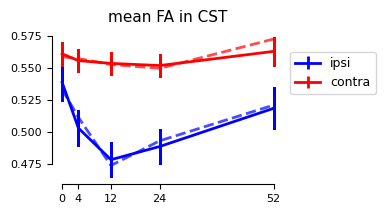

In [33]:
colours = ['r', 'b']
fig, ax = plt.subplots(figsize = (3,2))
ax.errorbar(x = lme[lme.regionname == 'CST_R']['Week'], y = lme[lme.regionname == 'CST_R']['beta'], yerr = lme[lme.regionname == 'CST_R']['se'], linewidth = 2, color = 'blue', label = 'ipsi')
ax.errorbar(x = lme[lme.regionname == 'CST_L']['Week'], y = lme[lme.regionname == 'CST_L']['beta'], yerr = lme[lme.regionname == 'CST_L']['se'], linewidth = 2, color = 'red', label = 'contra')

obs_R = obs[obs.regionname == 'CST_R'].groupby('Week')['mean'].mean().reset_index()
obs_L = obs[obs.regionname == 'CST_L'].groupby('Week')['mean'].mean().reset_index()

ax.plot(obs_R['Week'], obs_R['mean'], alpha = .7, linestyle = '--', color = 'blue', linewidth = 2)
ax.plot(obs_L['Week'], obs_L['mean'], alpha = .7, linestyle = '--', color = 'red', linewidth = 2)



ax.set_xticks(gl.weeks)
ax.legend(bbox_to_anchor = (1,.9))
sns.despine(trim = True)

plt.savefig('figure/mean_FA_CST.pdf', bbox_inches = 'tight')

plt.title("mean FA in CST")
plt.show()

FA ratio = FA_ipsi / FA_contra

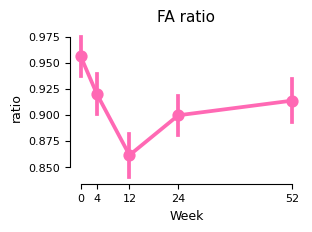

In [3]:
fig, ax = plt.subplots(figsize = (3,2))
sns.pointplot(x = 'Week', y = 'ratio', data = df, color = 'hotpink', native_scale = True, ax = ax, errorbar = 'se')

ax.set_xticks(gl.weeks)
sns.despine(trim = True)
plt.title("FA ratio")
plt.show()

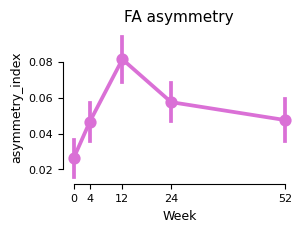

In [4]:
fig, ax = plt.subplots(figsize = (3,2))
sns.pointplot(x = 'Week', y = 'asymmetry_index', data = df, color = 'orchid', native_scale = True, ax = ax, errorbar = 'se')

ax.set_xticks(gl.weeks)
sns.despine(trim = True)
plt.title("FA asymmetry")
plt.show()